In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set clean styling for graphs
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (9, 5)

# Load dataset
df = pd.read_csv('ai4i2020.csv')

#for printing row and column
print(f"Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}")
df.head()

Total Rows: 10000, Total Columns: 14


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [2]:
# Check missing values
print("Missing values in dataset:\n", df.isnull().sum())

# Drop non-predictive columns and failure-leakage columns
# (TWF, HDF, PWF, OSF, RNF tell the answer directly, so they must be removed)
cols_to_drop = ['UDI', 'Product ID', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']
df_clean = df.drop(columns=cols_to_drop)

# Convert categorical 'Type' (L, M, H) into numeric dummy columns
df_clean = pd.get_dummies(df_clean, columns=['Type'], drop_first=True)

df_clean.head()

Missing values in dataset:
 UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,Type_L,Type_M
0,298.1,308.6,1551,42.8,0,0,False,True
1,298.2,308.7,1408,46.3,3,0,True,False
2,298.1,308.5,1498,49.4,5,0,True,False
3,298.2,308.6,1433,39.5,7,0,True,False
4,298.2,308.7,1408,40.0,9,0,True,False


In [3]:
# Temperature difference (Process Temp - Air Temp)
df_clean['Temp_Diff'] = df_clean['Process temperature [K]'] - df_clean['Air temperature [K]']

# Power factor = Torque * Rotational Speed
df_clean['Power_Factor'] = df_clean['Torque [Nm]'] * df_clean['Rotational speed [rpm]']

# Check how many machines actually failed
failure_counts = df_clean['Machine failure'].value_counts()
print(f"Healthy Machines (0): {failure_counts[0]}")
print(f"Failed Machines  (1): {failure_counts[1]} (~{failure_counts[1]/len(df_clean)*100:.2f}%)")

Healthy Machines (0): 9661
Failed Machines  (1): 339 (~3.39%)


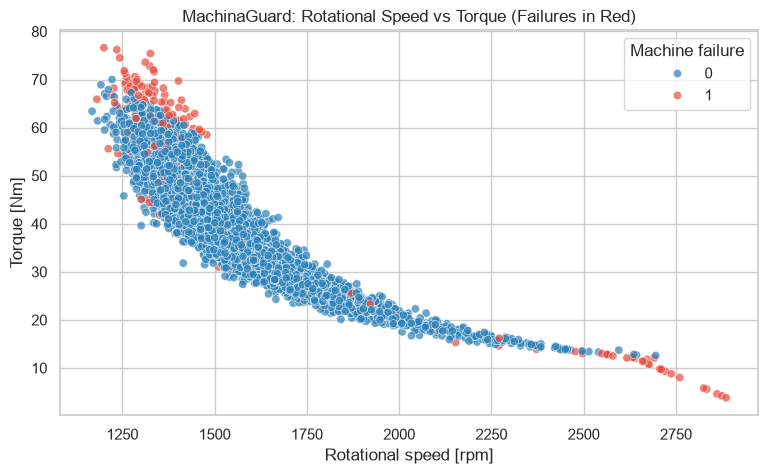

In [4]:
# Scatter plot showing where machines fail under torque vs speed
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df_clean,
    x='Rotational speed [rpm]',
    y='Torque [Nm]',
    hue='Machine failure',
    palette={0: '#2980b9', 1: '#e74c3c'},
    alpha=0.7
)
plt.title('MachinaGuard: Rotational Speed vs Torque (Failures in Red)')
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate inputs (X) and label (y)
X = df_clean.drop(columns=['Machine failure'])
y = df_clean['Machine failure']

# 80% Train, 20% Test with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Scale the data for distance-based models (KNN / SVM)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Data split successfully: {X_train.shape[0]} training samples, {X_test.shape[0]} testing samples.")

Data split successfully: 8000 training samples, 2000 testing samples.


In [6]:
import warnings
warnings.filterwarnings('ignore')
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Initialize the 3 syllabus models
models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Support Vector Machine": SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=42)
}

results = []

for name, model in models.items():
    # Train model
    model.fit(X_train_scaled, y_train)
    
    # Generate predictions
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    
    # Store metrics
    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred, zero_division=0), 4),
        "Recall": round(recall_score(y_test, y_pred), 4),
        "F1-Score": round(f1_score(y_test, y_pred), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_prob), 4)
    })

comparison_df = pd.DataFrame(results).set_index("Model")
comparison_df

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Decision Tree,0.9590,0.4470,0.8676,0.5900,0.8992
K-Nearest Neighbors,0.9755,0.8800,0.3235,0.4731,0.8671
Support Vector Machine,0.9195,0.2837,0.8971,0.4311,0.9706


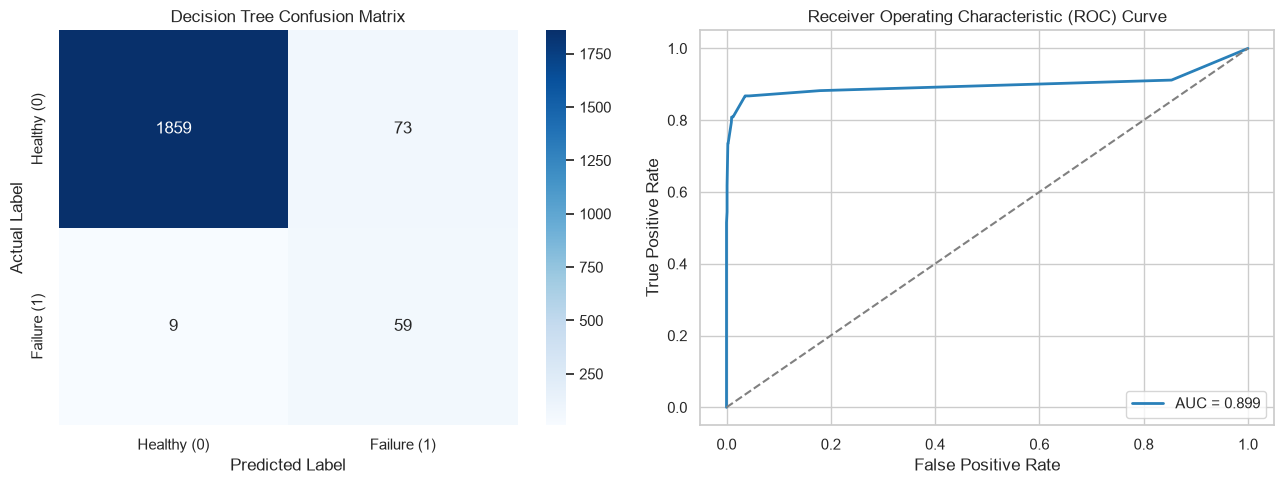

In [7]:
from sklearn.metrics import confusion_matrix, roc_curve

best_model = models["Decision Tree"]
y_pred_dt = best_model.predict(X_test_scaled)
y_prob_dt = best_model.predict_proba(X_test_scaled)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred_dt)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Healthy (0)', 'Failure (1)'],
            yticklabels=['Healthy (0)', 'Failure (1)'])
axes[0].set_title('Decision Tree Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('Actual Label')

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob_dt)
axes[1].plot(fpr, tpr, color='#2980b9', lw=2, label=f'AUC = {roc_auc_score(y_test, y_prob_dt):.3f}')
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--')
axes[1].set_title('Receiver Operating Characteristic (ROC) Curve')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()


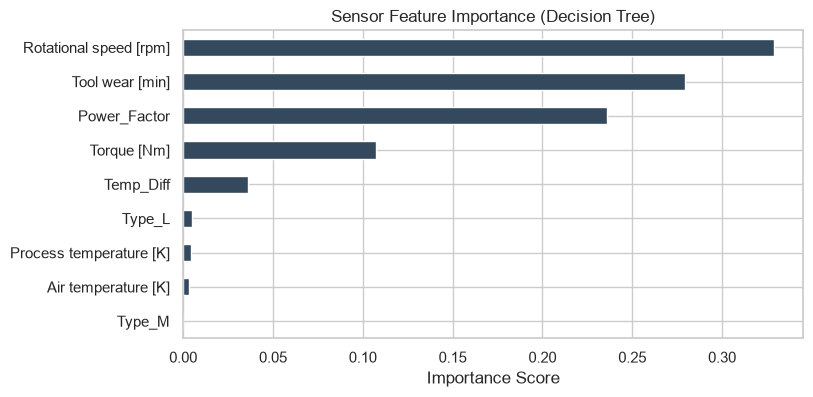

In [8]:
importances = pd.Series(best_model.feature_importances_, index=X.columns)
importances.sort_values().plot(kind='barh', color='#34495e', figsize=(8, 4))
plt.title("Sensor Feature Importance (Decision Tree)")
plt.xlabel("Importance Score")
plt.show()

Total operational points analyzed: 10000
Anomalies detected by DBSCAN (noise points): 8


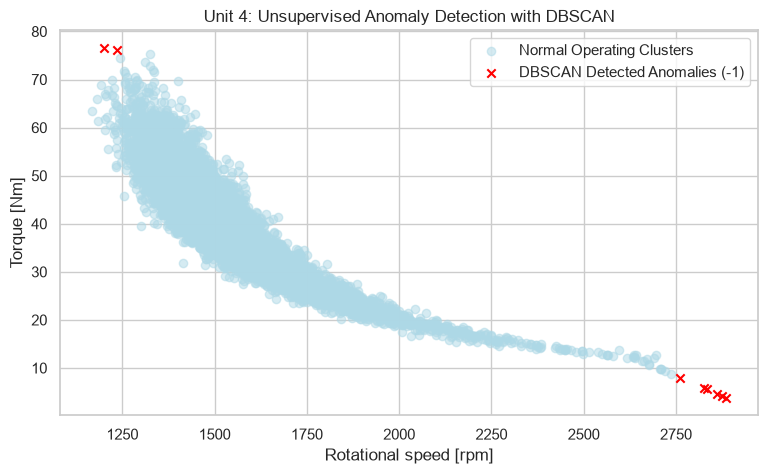

In [9]:
from sklearn.cluster import DBSCAN

# Use key physical mechanical features for clustering: Speed and Torque
X_cluster = df_clean[['Rotational speed [rpm]', 'Torque [Nm]']]
scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

# Run DBSCAN (eps: neighborhood radius, min_samples: core density threshold)
dbscan = DBSCAN(eps=0.45, min_samples=15)
df_clean['DBSCAN_Cluster'] = dbscan.fit_predict(X_cluster_scaled)

# Points with label -1 are detected as anomalies (noise)
anomalies = df_clean[df_clean['DBSCAN_Cluster'] == -1]
print(f"Total operational points analyzed: {len(df_clean)}")
print(f"Anomalies detected by DBSCAN (noise points): {len(anomalies)}")

# Plot clusters and anomalies
plt.figure(figsize=(9, 5))
plt.scatter(
    df_clean[df_clean['DBSCAN_Cluster'] != -1]['Rotational speed [rpm]'],
    df_clean[df_clean['DBSCAN_Cluster'] != -1]['Torque [Nm]'],
    c='lightblue', alpha=0.5, label='Normal Operating Clusters'
)
plt.scatter(
    anomalies['Rotational speed [rpm]'],
    anomalies['Torque [Nm]'],
    c='red', marker='x', label='DBSCAN Detected Anomalies (-1)'
)

plt.title('Unit 4: Unsupervised Anomaly Detection with DBSCAN')
plt.xlabel('Rotational speed [rpm]')
plt.ylabel('Torque [Nm]')
plt.legend()
plt.show()

In [10]:
import joblib

# Save the trained Decision Tree model and the scaler to disk
joblib.dump(best_model, 'machinaguard_model.pkl')
joblib.dump(scaler, 'machinaguard_scaler.pkl')

print("Model and Scaler successfully saved!")

Model and Scaler successfully saved!
